# 03 · Data cleaning

**Data science step 3 of 7:** turn the raw files into one clean table that we can trust.

**Input:** the 3 raw files
**Output:** `data/processed/stops.parquet`, one row per train, per journey date, per stop

What we fix, and why (each problem was found in notebooks 01 and 02):

| Problem | Decision |
|---|---|
| `train` loses leading zeros if read as a number | Read it as text |
| `dep_delay` is an exact copy of `arr_delay` | Drop it |
| 62 rows whose train + station are not in the timetable | Drop them |
| 3 trains pass through one station twice | Keep the first visit (prevents duplicate rows in joins) |
| The timetable has clock times only, no dates | Rebuild "minutes since the train left its origin" |
| **Fake zeros**: missing arrival times recorded as "on time" | Treat as missing |
| Delays of 1–3 days (185 rows) | Keep: the source confirms them |

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAW = Path("Indian-Railway-Network-and-Delays")
OUT = Path("data/processed")
FIGURES = Path("reports/figures")
OUT.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

## Step 1: Load the delay records
Only the columns we need. `dep_delay`, `sch_dep` and `act_dep` are left out (Check 5: departure delay = arrival delay).

In [2]:
delays = pd.read_csv(RAW / "train_routes_delays_Sep2024.csv", dtype={"train": str})
delays["date"] = pd.to_datetime(delays["date"])
delays = delays[["train", "date", "station", "sch_arr", "act_arr", "arr_delay"]]

print(delays.shape)
delays.head()

(1282325, 6)


,train,date,station,sch_arr,act_arr,arr_delay
0,12303,2024-09-02,HWH,08:00 AM,08:01 AM,0.0
1,12303,2024-09-02,BWN,09:05 AM,09:20 AM,15.0
2,12303,2024-09-02,DGR,09:57 AM,10:00 AM,3.0
3,12303,2024-09-02,ASN,10:32 AM,10:34 AM,2.0
4,12303,2024-09-02,CRJ,11:00 AM,11:04 AM,4.0


## Step 2: Load the timetable and rebuild scheduled time

The timetable gives every stop of every train, with **clock times only** (`"09:40 PM"`). To know how much journey time is left, we need **minutes since the train left its origin**.

Same idea as Check 6: each step of the journey (running between stations, waiting at a station) is calculated with `% 1440`, so crossing midnight works. Then the steps are added up.

In [3]:
def clock_to_minutes(times):
    # '09:40 PM' -> 1300 (minutes after midnight)
    t = pd.to_datetime(times, format="%I:%M %p")
    return t.dt.hour * 60 + t.dt.minute


routes = pd.read_csv(RAW / "train_routes_Sep2024.csv", dtype={"trainNumber": str})
routes = routes.sort_values(["trainNumber", "stnSerialNumber"]).reset_index(drop=True)

arr = clock_to_minutes(routes["arrivalTime"])
dep = clock_to_minutes(routes["departureTime"])
prev_dep = dep.groupby(routes["trainNumber"]).shift()          # departure from the previous station

wait = (dep - arr) % 1440                                       # time standing at a station
run = (arr - prev_dep) % 1440                                   # time travelling from the previous station
prev_wait = wait.groupby(routes["trainNumber"]).shift()

step = run.fillna(0) + prev_wait.fillna(0)                      # 0 for the first station
routes["sched_min"] = step.groupby(routes["trainNumber"]).cumsum()

routes.loc[routes["trainNumber"] == "12303",
           ["station_code", "arrivalTime", "departureTime", "distance", "sched_min"]].tail(6)

,station_code,arrivalTime,departureTime,distance,sched_min
21880,PRYJ,09:40 PM,09:45 PM,892,820.0
21881,CNB,12:02 AM,12:07 AM,1086,962.0
21882,ETW,01:29 AM,01:31 AM,1225,1049.0
21883,TDL,02:48 AM,02:50 AM,1317,1128.0
21884,ALJN,03:38 AM,03:40 AM,1395,1178.0
21885,NDLS,06:05 AM,06:05 AM,1527,1325.0


CNB is at 12:02 AM (after midnight) and `sched_min` keeps increasing: New Delhi is reached **1325 minutes** (22 h 5 min) after leaving Howrah. ✅

Now add per-train totals and remove the duplicate station visits (Check 8):

In [4]:
by_train = routes.groupby("trainNumber")
routes["n_stops"] = by_train["stnSerialNumber"].transform("max")
routes["total_km"] = by_train["distance"].transform("max")
routes["total_sched_min"] = by_train["sched_min"].transform("max")

print("duplicate train+station rows:", routes.duplicated(["trainNumber", "station_code"]).sum())
routes = routes.drop_duplicates(["trainNumber", "station_code"])

routes = routes.rename(columns={"trainNumber": "train", "station_code": "station",
                                "stnSerialNumber": "stop_no", "trainName": "train_name"})
routes = routes[["train", "station", "train_name", "stop_no", "distance",
                 "n_stops", "total_km", "sched_min", "total_sched_min"]]
routes.head()

duplicate train+station rows: 42


,train,station,train_name,stop_no,distance,n_stops,total_km,sched_min,total_sched_min
0,00961,MJ,Valley Queen Special,1,0,3,47,0.0,180.0
1,00961,FLD,Valley Queen Special,2,25,3,47,75.0,180.0
2,00961,KBK,Valley Queen Special,3,47,3,47,180.0,180.0
3,00962,KBK,Valley Queen Special,1,0,3,47,0.0,180.0
4,00962,FLD,Valley Queen Special,2,22,3,47,90.0,180.0


## Step 3: Join delays + timetable + zones
`how="inner"` keeps only rows found in both tables, which drops the 62 unmatched rows. **Check the row count after every join.**

In [5]:
stops = delays.merge(routes, on=["train", "station"], how="inner")
print(f"before join: {len(delays):,} rows | after join: {len(stops):,} rows | dropped: {len(delays) - len(stops)}")

with open(RAW / "stations_zones_mapping.json") as f:
    zones = json.load(f)
stops["zone"] = stops["station"].map(zones).fillna("UNKNOWN")
print("rows without a zone:", (stops["zone"] == "UNKNOWN").sum())

before join: 1,282,325 rows | after join: 1,282,263 rows | dropped: 62
rows without a zone: 0


## Step 4: Put every journey in stop order
A **trip** = one train on one date. `trip_id` names it, e.g. `12303_2024-09-02`.

In [6]:
stops["trip_id"] = stops["train"] + "_" + stops["date"].dt.strftime("%Y-%m-%d")
stops = stops.sort_values(["trip_id", "stop_no"]).reset_index(drop=True)
print(f"{stops['trip_id'].nunique():,} trips")

57,485 trips


## Step 5: Fake zeros

In notebook 02 (train 12130), some days went *hours late → exactly 0 → hours late again*. A train can't make up 20 hours and lose them again a few stations later.

**How do we tell a fake 0 from a real recovery?** After a stop that was at least *t* minutes late, compare:
- how often the next stop shows **exactly 0**, and
- how often the train **really recovers** that much but is still a bit late (a non-zero value).

In [7]:
prev_delay = stops.groupby("trip_id")["arr_delay"].shift()
drop = prev_delay - stops["arr_delay"]

rows = []
for t in [30, 60, 120]:
    after_big = prev_delay >= t
    rows.append({
        "previous stop at least (min)": t,
        "next stop is exactly 0 (%)": 100 * ((stops["arr_delay"] == 0) & after_big).sum() / after_big.sum(),
        "real recovery of that size, still > 0 (%)": 100 * ((drop >= t) & (stops["arr_delay"] > 0) & after_big).sum() / after_big.sum(),
    })
pd.DataFrame(rows).round(2)

,previous stop at least (min),next stop is exactly 0 (%),"real recovery of that size, still > 0 (%)"
0,30,8.68,5.53
1,60,7.04,1.28
2,120,5.73,0.12


After a stop **60+ minutes** late, an exact 0 happens about **7%** of the time, but a real 60+ minute recovery that stays above 0 only about **1.3%**. At 120+ minutes the gap is about **50×**. Exact zeros after a big delay are mostly missing data.

**Rule:** a 0 that comes after a stop at least **60 minutes** late (with only zeros in between) is set to missing.

How it works: for every 0, look back to the **last non-zero delay** in the same trip (`ffill` = copy the last known value forward):

In [8]:
THRESHOLD = 60

nonzero = stops["arr_delay"].where(stops["arr_delay"] > 0)          # zeros become NaN
last_nonzero = nonzero.groupby(stops["trip_id"]).ffill()            # last non-zero delay so far
stops["is_suspect_zero"] = (stops["arr_delay"] == 0) & (last_nonzero >= THRESHOLD)

stops["delay"] = stops["arr_delay"].mask(stops["is_suspect_zero"])   # cleaned delay (NaN = unknown)

print(f"fake zeros flagged: {stops['is_suspect_zero'].sum():,} ({100 * stops['is_suspect_zero'].mean():.1f}% of rows)")
stops.loc[stops["trip_id"] == "12295_2024-09-05", ["station", "arr_delay", "delay", "is_suspect_zero"]].iloc[10:20]

fake zeros flagged: 47,603 (3.7% of rows)


,station,arr_delay,delay,is_suspect_zero
264770,OGL,663.0,663.0,False
264771,BZA,659.0,659.0,False
264772,KMT,0.0,NaN,True
264773,WL,0.0,NaN,True
264774,RDM,0.0,NaN,True
264775,BPQ,0.0,NaN,True
264776,CD,0.0,NaN,True
264777,SEGM,0.0,NaN,True
264778,NGP,1834.0,1834.0,False
264779,BZU,1871.0,1871.0,False


Train 12295 from Check 6: `659 → 0 0 0 0 0 0 → 1834`. The six zeros are now `NaN`. The original value stays in `arr_delay`; the cleaned value is `delay`.

How much does the choice of 60 matter?

In [9]:
for t in [30, 60, 120]:
    n = ((stops["arr_delay"] == 0) & (last_nonzero >= t)).sum()
    print(f"threshold {t:>3} min -> {n:>7,} zeros flagged ({100 * n / len(stops):.1f}% of rows)")

threshold  30 min -> 101,644 zeros flagged (7.9% of rows)
threshold  60 min ->  47,603 zeros flagged (3.7% of rows)
threshold 120 min ->  21,379 zeros flagged (1.7% of rows)


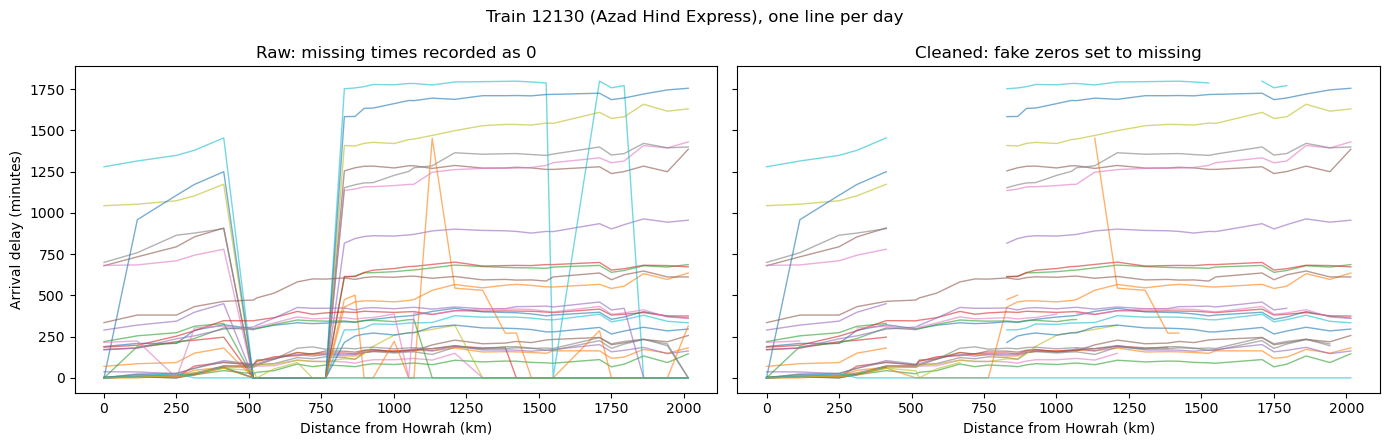

In [10]:
one = stops[stops["train"] == "12130"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, col, title in [(axes[0], "arr_delay", "Raw: missing times recorded as 0"),
                       (axes[1], "delay", "Cleaned: fake zeros set to missing")]:
    for _, trip in one.groupby("date"):
        ax.plot(trip["distance"], trip[col], alpha=0.6, lw=1)
    ax.set_title(title)
    ax.set_xlabel("Distance from Howrah (km)")
axes[0].set_ylabel("Arrival delay (minutes)")
fig.suptitle("Train 12130 (Azad Hind Express), one line per day")
fig.tight_layout()
fig.savefig(FIGURES / "fake_zeros_12130.png", dpi=120)
plt.show()

On the right, the lines no longer collapse to 0 between ~515 and ~800 km.

**Known limitation:** the rule needs an earlier late stop to compare with. Zeros at the **start** of a trip can't be detected (e.g. the line still sitting at 0 on the right).

## Step 6: Mark each trip's destination

In [11]:
last_stop = stops.groupby("trip_id")["stop_no"].transform("max")
stops["is_destination"] = stops["stop_no"] == last_stop

dest = stops[stops["is_destination"]]
print(f"{dest['delay'].isna().sum():,} of {len(dest):,} trips ({100 * dest['delay'].isna().mean():.1f}%) "
      "have no reliable destination delay -> they can't be used to train the model")

4,043 of 57,485 trips (7.0%) have no reliable destination delay -> they can't be used to train the model


## Step 7: Save
`parquet` is a fast, compressed file format that also remembers column types (unlike CSV, `train` stays text).

In [12]:
stops.to_parquet(OUT / "stops.parquet", index=False)

print(f"saved {len(stops):,} rows x {stops.shape[1]} columns")
stops.dtypes

saved 1,282,263 rows x 18 columns


train                         str
date               datetime64[us]
station                       str
sch_arr                       str
act_arr                       str
arr_delay                 float64
train_name                    str
stop_no                     int64
distance                    int64
n_stops                     int64
total_km                    int64
sched_min                 float64
total_sched_min           float64
zone                          str
trip_id                       str
is_suspect_zero              bool
delay                     float64
is_destination               bool
dtype: object

## Summary
| | |
|---|---|
| Clean rows | **1,282,263** |
| Trips | **57,485** |
| Fake zeros set to missing | **47,603** (3.7%) |
| New columns | `delay` (cleaned), `sched_min`, `total_sched_min`, `zone`, `trip_id`, `is_destination` |

**Next:** notebook 04 turns this table into model inputs.

### 🧠 Try it yourself
1. Draw the before/after chart for train **12295**. Does the cleaning catch its fake zeros?
2. Change `THRESHOLD` to 30 and to 120, re-run notebooks 03–07, and compare the final MAE. Which threshold would you defend?
3. Find a trip with a **real** 60+ minute recovery (the delay drops by 60+ but stays above 0). Where did it happen?